In [2]:
import numpy as np
import matplotlib.pyplot as plt

import millenium_bridge as mb

In [3]:
def add_pedestrians(sim: mb.MillenniumBridgeSim, n_add: int):
    """
    Add n_add new pedestrians:
      - fresh phases theta ~ Unif[-pi, pi]
      - fresh stepping frequencies omega ~ Normal(mean=omega_mean, std=sigma)
    """
    if n_add <= 0:
        return
    p = sim.params
    new_theta = sim.rng.uniform(-np.pi, np.pi, size=n_add)
    new_omega = sim.rng.normal(loc=p.omega_mean, scale=max(p.sigma, 1e-12), size=n_add)

    sim.theta = np.concatenate([sim.theta, new_theta])
    sim.omega = np.concatenate([sim.omega, new_omega])
    sim.N = sim.theta.size


def run_crowd_ramp(
    params: mb.BridgeParams,
    *,
    N0: int = 20,
    Nmax: int = 240,
    dN: int = 10,
    dT: float = 6.0,
    dt: float = 0.05,
    dt_int: float = 0.01,
    post_time: float = 15.0,
    seed: int = 42,
):
    """
    Controlled staircase crowd ramp:
      start at N0, every dT seconds increase by dN until Nmax,
      then simulate an additional post_time.

    Returns dict with arrays for t, N, A, R plus Nc and tc.
    """
    sim = mb.MillenniumBridgeSim(N=N0, params=params, seed=seed)

    Nc = mb.critical_crowd_size(params)  # theory Nc:contentReference[oaicite:5]{index=5}
    # total ramp duration
    n_steps = int(np.ceil(max(0, Nmax - N0) / dN))
    t_end = n_steps * dT + post_time

    t_hist, N_hist, A_hist, R_hist = [], [], [], []

    next_ramp_t = dT  # first increase happens at t=dT
    while sim.t < t_end - 1e-12:
        # apply ramp if time
        if (sim.t >= next_ramp_t - 1e-12) and (sim.N < Nmax):
            add_pedestrians(sim, min(dN, Nmax - sim.N))
            next_ramp_t += dT

        sim.step(dt, dt_int=dt_int)

        A, _Psi = mb.amp_phase(sim.X, sim.V, params.Omega)
        R, _Phi = mb.order_param(sim.theta)

        t_hist.append(sim.t)
        N_hist.append(sim.N)
        A_hist.append(A)
        R_hist.append(R)

    t = np.array(t_hist)
    N = np.array(N_hist, dtype=float)
    A = np.array(A_hist, dtype=float)
    R = np.array(R_hist, dtype=float)

    # tc = first time where N(t) >= Nc (as in assignment):contentReference[oaicite:6]{index=6}
    idx = np.where(N >= Nc)[0]
    tc = float(t[idx[0]]) if len(idx) else np.nan

    return {
        "t": t,
        "N": N,
        "A": A,
        "R": R,
        "Nc": float(Nc),
        "tc": tc,
        "params": params,
    }

In [4]:
params = mb.BridgeParams(
    M=1.0,
    f0_hz=1.0,
    zeta=0.02,
    G=0.015,        # force per pedestrian
    C=0.8,          # coupling sensitivity
    alpha=np.pi/2,  # assignment “simple case” mentions this:contentReference[oaicite:7]{index=7}
    sigma=0.60,     # cadence spread (rad/s)
    detune=0.0
)

out = run_crowd_ramp(
    params,
    N0=20, Nmax=240, dN=10, dT=6.0,
    dt=0.05, dt_int=0.01,
    post_time=15.0,
    seed=42
)

out["Nc"], out["tc"]

(125.99687956577935, 66.09999999999691)

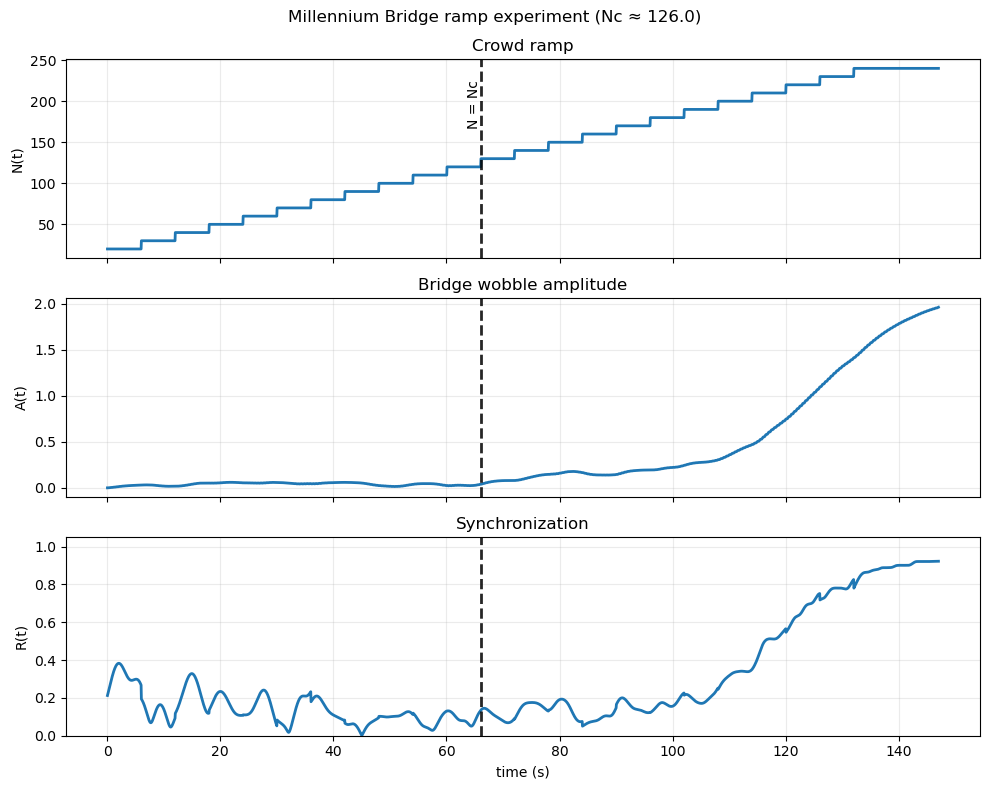

In [5]:
t, N, A, R = out["t"], out["N"], out["A"], out["R"]
Nc, tc = out["Nc"], out["tc"]

fig, axs = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

# N(t) staircase
axs[0].plot(t, N, lw=2)
axs[0].set_ylabel("N(t)")
axs[0].set_title("Crowd ramp")
axs[0].grid(True, alpha=0.25)

# A(t)
axs[1].plot(t, A, lw=2)
axs[1].set_ylabel("A(t)")
axs[1].set_title("Bridge wobble amplitude")
axs[1].grid(True, alpha=0.25)

# R(t)
axs[2].plot(t, R, lw=2)
axs[2].set_ylabel("R(t)")
axs[2].set_xlabel("time (s)")
axs[2].set_title("Synchronization")
axs[2].set_ylim(0, 1.05)
axs[2].grid(True, alpha=0.25)

# Vertical line at tc
if np.isfinite(tc):
    for ax in axs:
        ax.axvline(tc, color="black", linestyle="--", lw=2, alpha=0.85)
    axs[0].text(tc, axs[0].get_ylim()[1]*0.9, "N = Nc", rotation=90, va="top", ha="right")

fig.suptitle(f"Millennium Bridge ramp experiment (Nc ≈ {Nc:.1f})", y=0.98)
plt.tight_layout()
plt.show()

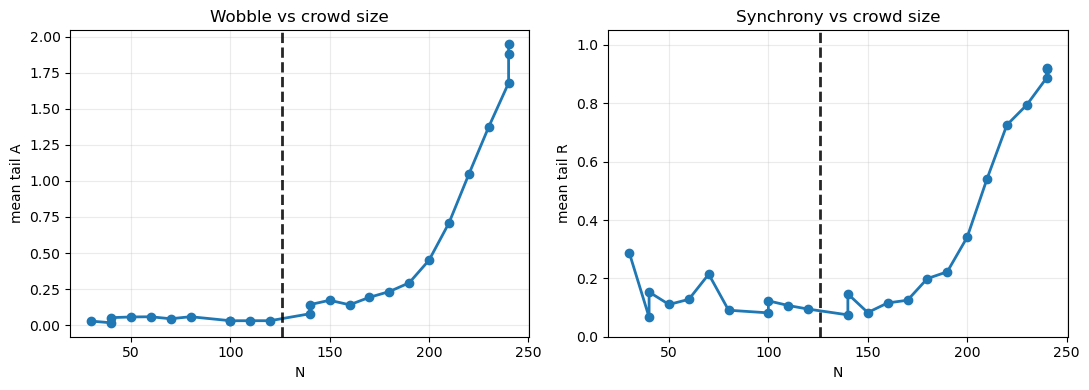

In [6]:
def stepwise_tail_means(t, N, y, dT, tail_s=1.5):
    """
    For each crowd step interval, compute mean of y over the last tail_s seconds of that step.
    Returns arrays N_step, y_step.
    """
    t0 = t[0]
    t_rel = t - t0

    # Identify step indices by floor(t_rel/dT)
    step_id = np.floor(t_rel / dT).astype(int)
    steps = np.unique(step_id)

    N_step, y_step = [], []
    for s in steps:
        mask = (step_id == s)
        if not np.any(mask):
            continue
        t_s = t_rel[mask]
        y_s = y[mask]
        N_s = N[mask][-1]

        t_end = t_s[-1]
        tail_mask = t_s >= (t_end - tail_s)
        if np.any(tail_mask):
            N_step.append(N_s)
            y_step.append(np.mean(y_s[tail_mask]))
    return np.array(N_step), np.array(y_step)


N_step, A_step = stepwise_tail_means(t, N, A, dT=6.0, tail_s=1.5)
_,      R_step = stepwise_tail_means(t, N, R, dT=6.0, tail_s=1.5)

fig, axs = plt.subplots(1, 2, figsize=(11, 4))

axs[0].plot(N_step, A_step, "o-", lw=2)
axs[0].axvline(Nc, color="black", linestyle="--", lw=2, alpha=0.85)
axs[0].set_xlabel("N")
axs[0].set_ylabel("mean tail A")
axs[0].set_title("Wobble vs crowd size")
axs[0].grid(True, alpha=0.25)

axs[1].plot(N_step, R_step, "o-", lw=2)
axs[1].axvline(Nc, color="black", linestyle="--", lw=2, alpha=0.85)
axs[1].set_xlabel("N")
axs[1].set_ylabel("mean tail R")
axs[1].set_title("Synchrony vs crowd size")
axs[1].set_ylim(0, 1.05)
axs[1].grid(True, alpha=0.25)

plt.tight_layout()
plt.show()

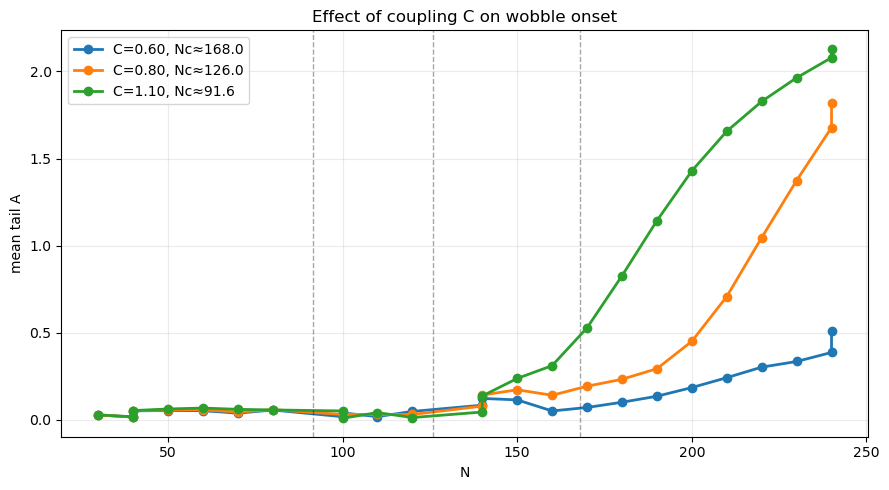

In [7]:
C_values = [0.6, 0.8, 1.1]

results = []
for C in C_values:
    p = mb.BridgeParams(
        M=1.0, f0_hz=1.0, zeta=0.02,
        G=0.015, C=C, alpha=np.pi/2,
        sigma=0.60, detune=0.0
    )
    outC = run_crowd_ramp(p, N0=20, Nmax=240, dN=10, dT=6.0, dt=0.05, dt_int=0.01, post_time=10.0, seed=42)
    t, N, A = outC["t"], outC["N"], outC["A"]
    N_step, A_step = stepwise_tail_means(t, N, A, dT=6.0, tail_s=1.5)
    results.append((C, outC["Nc"], N_step, A_step))

plt.figure(figsize=(9, 5))
for C, NcC, N_step, A_step in results:
    plt.plot(N_step, A_step, "o-", lw=2, label=f"C={C:.2f}, Nc≈{NcC:.1f}")
    plt.axvline(NcC, color="black", linestyle="--", lw=1, alpha=0.35)

plt.xlabel("N")
plt.ylabel("mean tail A")
plt.title("Effect of coupling C on wobble onset")
plt.grid(True, alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

## Critical values

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


import importlib.util, sys, pathlib

module_path = pathlib.Path("millenium_bridge.py")
if not module_path.exists():
    module_path = pathlib.Path("/mnt/data/millenium_bridge.py")

spec = importlib.util.spec_from_file_location("millenium_bridge", str(module_path))
mb = importlib.util.module_from_spec(spec)
sys.modules["millenium_bridge"] = mb
spec.loader.exec_module(mb)

# ---- Parameters (pick a set that gives a sane Nc in the middle of your sweep) ----
params = mb.BridgeParams(
    M=1.0,
    f0_hz=1.0,
    zeta=0.02,
    G=0.015,
    C=0.80,
    alpha=np.pi/2,
    sigma=0.60,
    detune=0.0
)

Nc = mb.critical_crowd_size(params)
print(f"Theoretical critical crowd size Nc ≈ {Nc:.2f}")

Theoretical critical crowd size Nc ≈ 126.00


In [9]:
def tail_rms(x: np.ndarray) -> float:
    return float(np.sqrt(np.mean(np.square(x))))

def bif_point_for_N(
    N: int,
    params: mb.BridgeParams,
    *,
    T: float = 60.0,        # total sim time
    dt: float = 0.05,       # output timestep
    dt_int: float = 0.01,   # integrator substep
    tail_s: float = 15.0,   # tail window for steady measurement
    seed: int = 42
):
    sim = mb.MillenniumBridgeSim(N=int(N), params=params, seed=seed)

    A_hist = []
    t_hist = []

    while sim.t < T - 1e-12:
        sim.step(dt, dt_int=dt_int)
        A, _ = mb.amp_phase(sim.X, sim.V, params.Omega)
        A_hist.append(A)
        t_hist.append(sim.t)

    A_hist = np.asarray(A_hist)
    t_hist = np.asarray(t_hist)

    tail_mask = t_hist >= (T - tail_s)
    A_tail = A_hist[tail_mask]

    return tail_rms(A_tail)

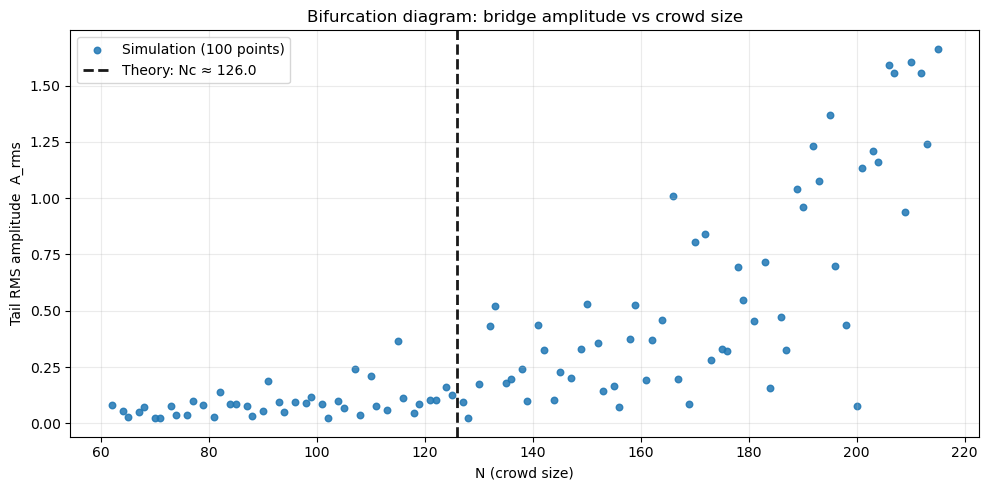

In [10]:
# 100 N values (center the range around Nc so the plot is actually informative)
N_min = max(10, int(np.floor(0.5 * Nc)))
N_max = min(800, int(np.ceil(1.7 * Nc)))
N_vals = np.rint(np.linspace(N_min, N_max, 100)).astype(int)

A_pts = np.empty_like(N_vals, dtype=float)

for i, N in enumerate(N_vals):
    # vary seed slightly so you see scatter rather than one frozen universe
    A_pts[i] = bif_point_for_N(N, params, T=60.0, dt=0.05, dt_int=0.01, tail_s=15.0, seed=1000 + i)

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(N_vals, A_pts, s=22, alpha=0.85, label="Simulation (100 points)")
ax.axvline(Nc, color="black", linestyle="--", lw=2.0, alpha=0.9, label=f"Theory: Nc ≈ {Nc:.1f}")

ax.set_title("Bifurcation diagram: bridge amplitude vs crowd size")
ax.set_xlabel("N (crowd size)")
ax.set_ylabel("Tail RMS amplitude  A_rms")
ax.grid(True, alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

In [11]:
def gaussian_pdf(omega, mu, sigma):
    sigma = max(float(sigma), 1e-12)
    return (1.0/(sigma*np.sqrt(2*np.pi))) * np.exp(-0.5*((omega-mu)/sigma)**2)

def P_at_Omega_via_integral(Omega, mu, sigma, eps=None, n=20001):
    """
    Numerically estimate P(Omega) using a small-window integral:
      P(Omega) ≈ (1/(2 eps)) ∫_{Omega-eps}^{Omega+eps} g(ω) dω
    """
    Omega = float(Omega); mu = float(mu); sigma = float(sigma)
    if eps is None:
        eps = 1e-3 * max(sigma, 1.0)  # small, but not suicidal
    eps = float(eps)

    w = np.linspace(Omega - eps, Omega + eps, int(n))
    g = gaussian_pdf(w, mu, sigma)
    integral = np.trapz(g, w)
    return integral / (2.0 * eps)

P_Om_num = P_at_Omega_via_integral(params.Omega, params.omega_mean, params.sigma)
P_Om_exact = mb.normal_pdf(params.Omega, params.omega_mean, params.sigma)

print(f"P(Omega) numeric ≈ {P_Om_num:.8f}")
print(f"P(Omega) exact   ≈ {P_Om_exact:.8f}")
print(f"relative error   ≈ {(P_Om_num/P_Om_exact - 1):.3e}")

P(Omega) numeric ≈ 0.66490349
P(Omega) exact   ≈ 0.66490380
relative error   ≈ -4.630e-07


/var/folders/z4/nl4m_8q17pxg6zl3ln3klpq00000gn/T/ipykernel_62461/2758855725.py:17: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  integral = np.trapz(g, w)


In [12]:
def C_crit_for_N(params: mb.BridgeParams, N: float):
    P = P_at_Omega_via_integral(params.Omega, params.omega_mean, params.sigma)
    denom = np.pi * max(params.G, 1e-12) * max(N, 1e-12) * max(P, 1e-18)
    return 2.0 * params.B * params.Omega / denom

# Choose the crowd size you want to reference (change this if you want)
N_ref = 200
Ccrit = C_crit_for_N(params, N_ref)

print(f"For N = {N_ref}, critical coupling Ccrit ≈ {Ccrit:.4f}")

For N = 200, critical coupling Ccrit ≈ 0.5040


/var/folders/z4/nl4m_8q17pxg6zl3ln3klpq00000gn/T/ipykernel_62461/2758855725.py:17: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  integral = np.trapz(g, w)


/var/folders/z4/nl4m_8q17pxg6zl3ln3klpq00000gn/T/ipykernel_62461/2758855725.py:17: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  integral = np.trapz(g, w)


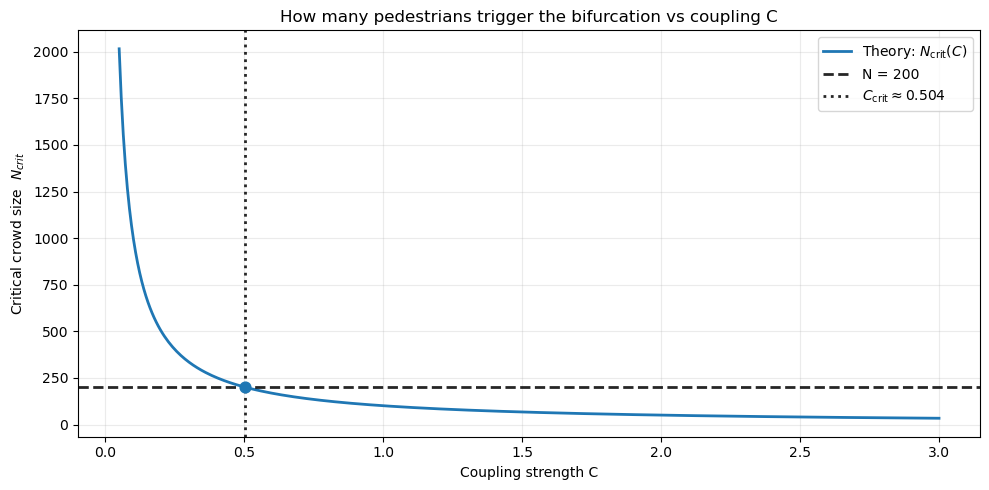

In [13]:
def N_crit_for_C(params: mb.BridgeParams, C: float):
    P = P_at_Omega_via_integral(params.Omega, params.omega_mean, params.sigma)
    denom = np.pi * max(params.G, 1e-12) * max(C, 1e-12) * max(P, 1e-18)
    return 2.0 * params.B * params.Omega / denom

# Sweep C
C_vals = np.linspace(0.05, 3.0, 400)
Ncrit_vals = np.array([N_crit_for_C(params, C) for C in C_vals])

# Mark the critical point that corresponds to N_ref
Ccrit = C_crit_for_N(params, N_ref)

plt.figure(figsize=(10, 5))
plt.plot(C_vals, Ncrit_vals, lw=2, label=r"Theory: $N_{\mathrm{crit}}(C)$")

plt.axhline(N_ref, color="black", linestyle="--", lw=2, alpha=0.85, label=f"N = {N_ref}")
plt.axvline(Ccrit, color="black", linestyle=":",  lw=2, alpha=0.85, label=fr"$C_{{\mathrm{{crit}}}} \approx {Ccrit:.3f}$")

plt.scatter([Ccrit], [N_ref], s=60, zorder=5)

plt.xlabel("Coupling strength C")
plt.ylabel("Critical crowd size  $N_{crit}$")
plt.title("How many pedestrians trigger the bifurcation vs coupling C")
plt.grid(True, alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()